# 05 · Results

**Question.** Does the list win more money than simple rules, and are its chances right?

**Answer.**
- **H1 holds.** First call wins 81% of available dollars vs 64% for newest or biggest first: +16.9
  and +16.4 points, at least +11.7 under a strict (Bonferroni) range.
- **H2 fails.** *Days waiting × amount* ranks as well (−0.2 points, range −1.8 to +1.2).
- **H3 mostly holds.** Chances miss in 3 of 101 groups, against 39 for the simple list.

**Method.** Replay of every 8am from 1 September to 20 December 2024, relearning on the first of each
month from settled quotes. A business-morning counts when two or more quotes are waiting. Dollars won
= dollars from the chosen quote over the most any single pick could have won, summed over mornings.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import figures
import pandas as pd
import style
from IPython.display import Image, display

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
style.apply()
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

import sensitivity

from quote_followup import backtest
from quote_followup.scorers import BIGGEST_FIRST, NEWEST_FIRST

ev = backtest.evaluate(quotes, settings)

## 1. All methods

In [2]:
columns = [
    "scorer",
    "k",
    "dollar_capture",
    "dollar_capture_lo",
    "dollar_capture_hi",
    "hit_rate",
    "hit_rate_lo",
    "hit_rate_hi",
]
backtest.for_people(ev.summary[columns]).round(3)

,way of ordering,calls,dollars won,dollars low,dollars high,yes rate,yes low,yes high
0,Our list: chance x amount,1,0.809,0.781,0.836,0.359,0.342,0.376
1,"Our list, by chance only",1,0.622,0.586,0.657,0.443,0.426,0.459
2,"Our list, ignoring days without a reply",1,0.660,0.618,0.697,0.219,0.204,0.237
3,Days without a reply x amount,1,0.811,0.781,0.839,0.359,0.342,0.376
4,Biggest quote first,1,0.645,0.599,0.685,0.210,0.194,0.228
5,Newest quote first,1,0.640,0.601,0.676,0.425,0.409,0.442
6,Random order,1,0.377,0.342,0.409,0.245,0.229,0.262
7,Our list: chance x amount,3,0.913,0.881,0.942,0.307,0.284,0.332
8,"Our list, by chance only",3,0.851,0.816,0.891,0.340,0.316,0.363
9,"Our list, ignoring days without a reply",3,0.843,0.808,0.872,0.216,0.195,0.237


## 2. H1: against the rules of thumb

In [3]:
backtest.for_people(ev.comparisons.iloc[:2]).round(3)

,this order,compared with,measure,calls,difference,low,high
0,Our list: chance x amount,Newest quote first,dollars won,1,0.169,0.134,0.202
1,Our list: chance x amount,Biggest quote first,dollars won,1,0.164,0.129,0.200


In [4]:
backtest.strict_lead(ev.summary, [NEWEST_FIRST, BIGGEST_FIRST]).round(3)

,our lead,low (strict),high (strict)
compared with,,,
Newest quote first,0.169,0.126,0.211
Biggest quote first,0.164,0.117,0.212


The lead holds under the strict range. On the average of per-morning shares, which weighs a \$60 morning like a \$6,000 one, the order reverses:

In [5]:
ev.first_measure.round(3).rename("average of per-morning shares")

scorer
Our list: chance x amount                  0.665
Our list, by chance only                   0.726
Our list, ignoring days without a reply    0.413
Days without a reply x amount              0.664
Biggest quote first                        0.396
Newest quote first                         0.710
Random order                               0.398
Name: average of per-morning shares, dtype: float64

## 3. H2: against days waiting × amount

In [6]:
backtest.for_people(ev.comparisons.iloc[2:4]).round(4)

,this order,compared with,measure,calls,difference,low,high
2,Our list: chance x amount,Days without a reply x amount,dollars won,1,-0.0021,-0.0179,0.0119
3,Our list: chance x amount,Days without a reply x amount,dollars won,3,-0.0027,-0.0158,0.0087


No difference in dollars. On yes rate, ranking by chance beats newest first at one call only:

In [7]:
backtest.for_people(ev.comparisons.iloc[4:]).round(4)

,this order,compared with,measure,calls,difference,low,high
4,Our list: chance x amount,Newest quote first,yes rate,1,-0.0659,-0.0765,-0.0549
5,"Our list, by chance only",Newest quote first,yes rate,1,0.0180,0.0118,0.0238
6,"Our list, by chance only",Newest quote first,yes rate,3,0.0020,-0.0006,0.0046


## 4. H3: are the chances right?

In [8]:
backtest.for_people(ev.quality).round(3)

,our model,days waiting only
quote-mornings scored,75406.000,75406.000
different quotes,9522.000,9522.000
"AUC, every waiting morning counted",0.870,0.849
AUC of days waiting alone,0.849,0.849
"AUC, each quote counted once",0.691,0.542
"AUC among quotes the same age, lowest",0.665,0.496
"AUC among quotes the same age, highest",0.693,0.634
log loss (lower is better),0.374,0.396
Brier score (lower is better),0.121,0.130
average gap between chance and reality,0.007,0.003


Both are calibrated on average (gap under one point), so the average cannot separate them; groups can.
Fair discrimination figures are *each quote counted once* (0.69) and *same-age* (0.66 to 0.69); the
pooled 0.87 counts long-ignored quotes many times.

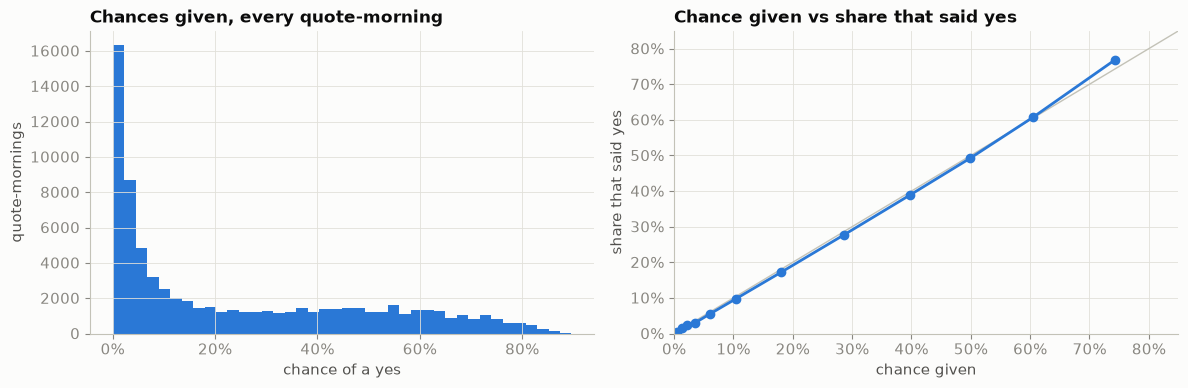

In [9]:
figures.chance_check(ev.result.predictions)

Groups missed beyond chance:

In [10]:
threshold = ev.quality.loc["subgroup_z_threshold", "our model"]
ev.subgroups[ev.subgroups["z"].abs() > threshold].round(3)

,workflow_type,split,level,age_band,rows,quotes,predicted,observed,gap,z
48,recurring,customer_channel,marketplace,"(14.0, 30.0]",1971,140,0.006,0.001,-0.005,-4.492
69,recurring,customer_channel,repeat_offline,"(3.0, 7.0]",200,79,0.547,0.790,0.243,4.171
97,recurring,send_speed,within a day,"(1.0, 3.0]",1512,926,0.633,0.689,0.056,3.574


Two are recurring quotes from repeat or fast-sent customers at 1 to 7 quiet days (underrated); the third is a sub-1-point gap near zero.

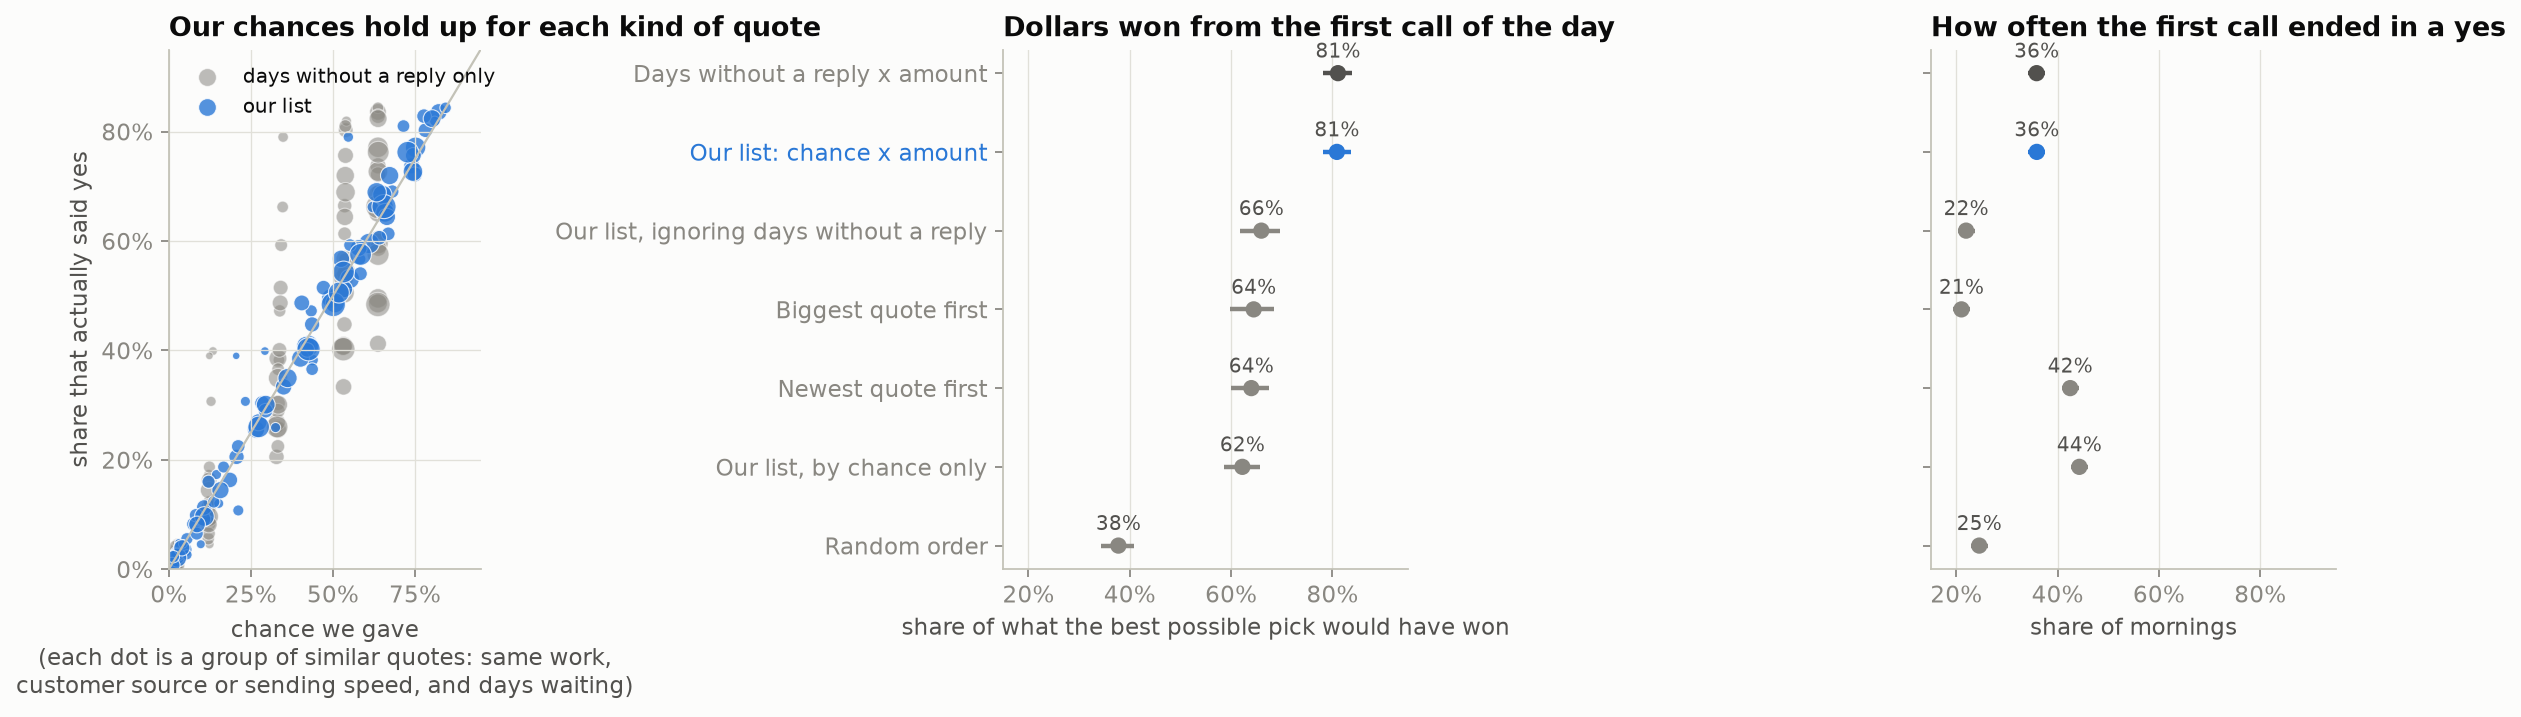

In [11]:
figures.evidence(ev.summary, ev.subgroups, ev.simple_subgroups)
display(Image("../assets/evidence.png"))

## 5. Stability by month (dollars won, first call)

In [12]:
ev.monthly.query("k == 1").pivot(index="month", columns="scorer", values="dollar_capture").round(3)

scorer,Biggest quote first,Days without a reply x amount,Newest quote first,"Our list, by chance only","Our list, ignoring days without a reply",Our list: chance x amount,Random order
month,,,,,,,
2024-09,0.689,0.858,0.654,0.625,0.702,0.831,0.378
2024-10,0.675,0.844,0.691,0.699,0.692,0.847,0.380
2024-11,0.575,0.800,0.646,0.628,0.586,0.802,0.379
2024-12,0.658,0.748,0.568,0.535,0.678,0.758,0.373


Ahead of both rules of thumb every month.

## 6. Sensitivity to judgement calls

In [13]:
sensitivity.run(quotes, settings).round(3)

,what changed,our list,days waiting x amount,best rule of thumb,its dollars won,our lead over it,lead low,lead high,lead over days waiting x amount,average chance gap,groups missed beyond luck
0,nothing (as built),0.809,0.811,Biggest quote first,0.645,0.164,0.123,0.203,-0.002,0.007,3
1,stale open quotes counted as lost,0.803,0.802,Newest quote first,0.642,0.161,0.128,0.193,0.001,0.005,2
2,"wait 60 days, not 45, before learning from a quote",0.807,0.811,Biggest quote first,0.645,0.163,0.123,0.202,-0.004,0.007,3
3,"reply speeds may use groups of 50 quotes, not 200",0.809,0.811,Biggest quote first,0.645,0.164,0.123,0.203,-0.002,0.007,3
4,reply speeds also learned by customer source,0.811,0.811,Biggest quote first,0.645,0.166,0.128,0.205,0.000,0.007,5


The lead stays about 16 points and calibration stays under one point in every variant.